**Segmentasi Citra Berbasis Similaritas: Region Growing**

---

### 1. Konsep Region Growing

Region Growing adalah metode segmentasi berbasis similaritas di mana piksel-piksel yang memiliki karakteristik serupa (biasanya intensitas) dikumpulkan menjadi satu wilayah (region) yang besar. Proses ini dimulai dari satu atau lebih titik awal (seed points), lalu region diperluas dengan menambahkan piksel-piksel tetangga yang memenuhi kriteria kesamaan tertentu.

---

### 2. Langkah-Langkah Algoritma Region Growing

1. Pilih satu atau lebih titik awal (seed).
2. Bandingkan piksel tetangga dari region dengan ambang batas kesamaan.
3. Tambahkan piksel yang mirip ke dalam region.
4. Ulangi proses untuk piksel baru dalam region sampai tidak ada lagi yang bisa ditambahkan.

---

### 3. Contoh Implementasi Python

```python
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi region growing
def region_growing(img, seed, threshold):
    rows, cols = img.shape
    segmented = np.zeros_like(img, dtype=np.uint8)
    segmented[seed] = 255

    region_mean = float(img[seed])
    queue = [seed]

    while queue:
        x, y = queue.pop(0)
        for dx in [-1, 0, 1]:
            for dy in [-1, 0, 1]:
                nx, ny = x + dx, y + dy
                if (0 <= nx < rows and 0 <= ny < cols and segmented[nx, ny] == 0):
                    diff = abs(int(img[nx, ny]) - region_mean)
                    if diff < threshold:
                        segmented[nx, ny] = 255
                        queue.append((nx, ny))
                        region_mean = (region_mean + int(img[nx, ny])) / 2
    return segmented

# Baca citra grayscale
img = cv2.imread('image.jpg', 0)

# Tentukan seed point dan threshold
seed_point = (100, 150)
threshold = 10

# Proses segmentasi
result = region_growing(img, seed_point, threshold)

# Visualisasi
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result, cmap='gray')
plt.title('Hasil Region Growing')
plt.axis('off')
plt.show()
```

---

### 4. Eksperimen Visual dan Parameter

```python
for t in [5, 10, 20]:
    segmented = region_growing(img, seed_point, threshold=t)
    plt.figure()
    plt.imshow(segmented, cmap='gray')
    plt.title(f'Threshold = {t}')
    plt.axis('off')
    plt.show()
```

Eksperimen ini menunjukkan bagaimana sensitivitas threshold mempengaruhi luas dan detail dari hasil segmentasi. Semakin besar threshold, semakin banyak piksel yang dimasukkan ke dalam region.

---

### 5. Integrasi dengan Thresholding dan Deteksi Tepi

Region Growing dapat digunakan bersama metode lain untuk memperbaiki akurasi segmentasi.

#### Region Growing + Thresholding :
```python
_, binary_mask = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY)
pre_masked = cv2.bitwise_and(img, img, mask=binary_mask)
region = region_growing(pre_masked, (100, 150), 10)

plt.imshow(region, cmap='gray')
plt.title('Region Growing + Thresholding')
plt.axis('off')
plt.show()
```

#### Region Growing + Deteksi Tepi :
```python
edges = cv2.Canny(img, 50, 150)
region = region_growing(img, (100, 150), 10)
combined = cv2.bitwise_and(region, edges)

plt.imshow(combined, cmap='gray')
plt.title('Region Growing + Canny Edge')
plt.axis('off')
plt.show()
```

---

### 5. Kesimpulan

* Region Growing adalah metode segmentasi intuitif dan sederhana yang cocok digunakan untuk citra dengan kontras intensitas yang cukup jelas antara objek dan latar belakang.
* Kualitas segmentasi sangat sensitif atau dipengaruhi oleh pemilihan seed dan ambang batas (threshold).
* Metode ini dapat digunakan sebagai bagian dari sistem segmentasi hibrida bersama dengan thresholding atau deteksi tepi.
* Pada domain medis, segmentasi ini dapat diterapkan pada citra MRI, CT, atau retina dengan preprocessing yang sesuai.

In [1]:
# Implementasi dan Eksperimen
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time

def show_grid(images, titles, cols=4, size=3.2, cmap='gray', suptitle=None):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(size * cols, size * rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap=None if im.ndim == 3 else cmap)
        plt.title(t, fontsize=9)
        plt.axis('off')
    if suptitle:
        plt.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

def overlay(rgb, mask, color=(255, 0, 0), alpha=0.45):
    out = rgb.copy().astype(np.float32)
    out[mask > 0] = (1 - alpha) * out[mask > 0] + alpha * np.array(color, np.float32)
    return out.astype(np.uint8)

def area_pct(mask):
    return 100.0 * np.count_nonzero(mask) / mask.size

Ukuran citra: (695, 735) | mean = 68.27 | std = 54.83

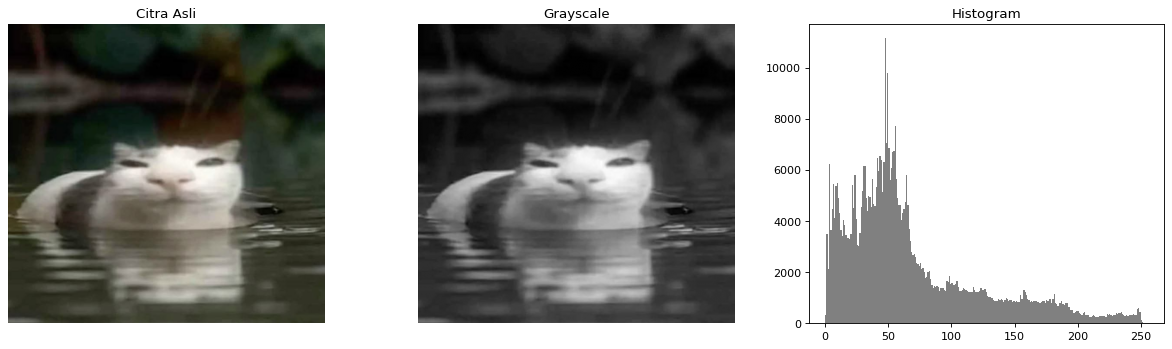

In [2]:
img_color = cv2.imread('gato.jpg')
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
img = cv2.imread('gato.jpg', 0)
print('Ukuran citra:', img.shape, '| mean = %.2f | std = %.2f' % (img.mean(), img.std()))

plt.figure(figsize=(15, 4.5))
plt.subplot(1, 3, 1), plt.imshow(img_rgb), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(img, cmap='gray'), plt.title('Grayscale'), plt.axis('off')
plt.subplot(1, 3, 3), plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray'), plt.title('Histogram')
plt.tight_layout()
plt.show()

Intensitas seed: 249
Waktu: 0.07 s | luas region: 7.62%

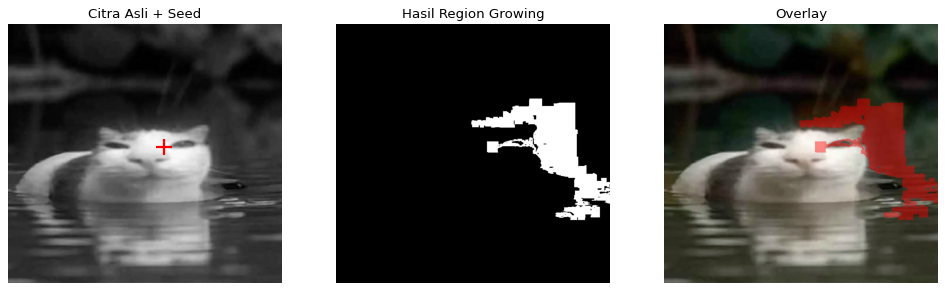

In [3]:
# A. Implementasi Region Growing (template)
def region_growing(img, seed, threshold):
    rows, cols = img.shape
    segmented = np.zeros_like(img, dtype=np.uint8)
    segmented[seed] = 255

    region_mean = float(img[seed])
    queue = [seed]

    while queue:
        x, y = queue.pop(0)
        for dx in [-1, 0, 1]:
            for dy in [-1, 0, 1]:
                nx, ny = x + dx, y + dy
                if (0 <= nx < rows and 0 <= ny < cols and segmented[nx, ny] == 0):
                    diff = abs(int(img[nx, ny]) - region_mean)
                    if diff < threshold:
                        segmented[nx, ny] = 255
                        queue.append((nx, ny))
                        region_mean = (region_mean + int(img[nx, ny])) / 2
    return segmented

seed_point = (330, 420)
threshold = 10
print('Intensitas seed:', img[seed_point])

t0 = time.time()
result = region_growing(img, seed_point, threshold)
print('Waktu: %.2f s | luas region: %.2f%%' % (time.time() - t0, area_pct(result)))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray'), plt.plot(seed_point[1], seed_point[0], 'r+', ms=15, mew=2)
plt.title('Citra Asli + Seed'), plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(result, cmap='gray'), plt.title('Hasil Region Growing'), plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(overlay(img_rgb, result)), plt.title('Overlay'), plt.axis('off')
plt.show()

In [4]:
# A.2 Region growing versi eksperimen
# Catatan fungsi template:
# 1. region_mean = (region_mean + nilai_baru) / 2 bukan rata-rata region sebenarnya (moving average bobot 0.5),
#    sehingga region mudah "drift" ke intensitas lain.
# 2. queue.pop(0) pada list berkompleksitas O(n) -> lambat untuk region besar, diganti deque.
# urutan tetangga dibuat sama dengan template (dx, dy dari -1..1) agar hasil kriteria 'template' identik
N8 = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
N4 = [(-1, 0), (0, -1), (0, 1), (1, 0)]

def region_growing_ex(img, seeds, threshold, criterion='template', connectivity=8, barrier=None):
    """
    criterion : 'template' -> running mean seperti template ((mean + x)/2)
                'mean'     -> rata-rata kumulatif region yang sebenarnya
                'seed'     -> dibandingkan dengan nilai seed (tetap)
                'neighbor' -> dibandingkan dengan piksel tetangga yang menambahkannya (local)
    img dapat berupa grayscale (H,W) atau multi-kanal (H,W,C) -> jarak Euclidean.
    barrier   : mask boolean; piksel True tidak boleh dimasuki (misal tepi Canny).
    """
    if isinstance(seeds, tuple):
        seeds = [seeds]
    im = img.astype(np.float64)
    if im.ndim == 2:
        im = im[..., None]
    rows, cols, nch = im.shape
    # konversi ke list Python agar akses per-piksel jauh lebih cepat dibanding indexing numpy
    px = im.reshape(-1, nch).tolist()
    bar = barrier.ravel().tolist() if barrier is not None else None
    seg = bytearray(rows * cols)
    nbrs = N8 if connectivity == 8 else N4
    thr2 = threshold ** 2
    q = deque()
    for s in seeds:
        seg[s[0] * cols + s[1]] = 1
        q.append(s)
    seed_val = [sum(px[s[0] * cols + s[1]][c] for s in seeds) / len(seeds) for c in range(nch)]
    region_mean = list(seed_val)
    total, n = [v * len(seeds) for v in seed_val], len(seeds)
    while q:
        x, y = q.popleft()
        cur = px[x * cols + y]
        for dx, dy in nbrs:
            nx, ny = x + dx, y + dy
            if 0 <= nx < rows and 0 <= ny < cols:
                k = nx * cols + ny
                if seg[k] or (bar is not None and bar[k]):
                    continue
                v = px[k]
                ref = seed_val if criterion == 'seed' else cur if criterion == 'neighbor' else region_mean
                if sum((a - b) ** 2 for a, b in zip(v, ref)) < thr2:
                    seg[k] = 1
                    q.append((nx, ny))
                    if criterion == 'template':
                        region_mean = [(a + b) / 2 for a, b in zip(region_mean, v)]
                    elif criterion == 'mean':
                        total = [a + b for a, b in zip(total, v)]
                        n += 1
                        region_mean = [a / n for a in total]
    return np.frombuffer(bytes(seg), np.uint8).reshape(rows, cols) * 255

t0 = time.time()
r_ex = region_growing_ex(img, seed_point, 10, criterion='template')
print('Versi deque: %.2f s | sama dengan template: %s' % (time.time() - t0, np.array_equal(r_ex, result)))

Versi deque: 0.22 s | sama dengan template: True

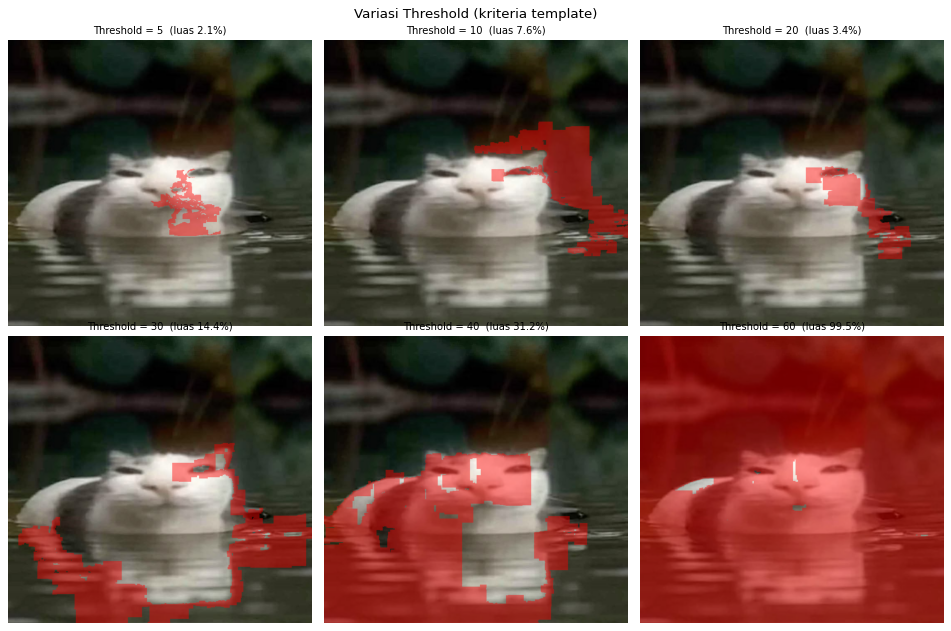

   T | luas (%) | waktu (s)
   5 |     2.12 |      0.15
  10 |     7.62 |      0.24
  20 |     3.43 |      0.17
  30 |    14.36 |      0.27
  40 |    31.18 |      0.44
  60 |    99.52 |      1.07

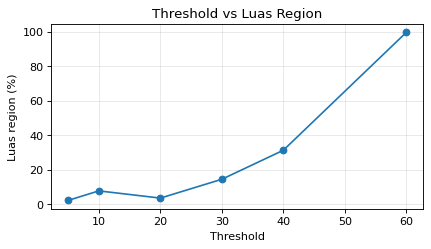

In [5]:
# B. Eksperimen Visual dan Parameter
# B.1 Variasi threshold (sesuai template + nilai tambahan)
thresholds = [5, 10, 20, 30, 40, 60]
ims, tts, stats = [], [], []
for t in thresholds:
    t0 = time.time()
    segmented = region_growing_ex(img, seed_point, threshold=t, criterion='template')
    dt = time.time() - t0
    stats.append((t, area_pct(segmented), dt))
    ims.append(overlay(img_rgb, segmented))
    tts.append(f'Threshold = {t}  (luas {area_pct(segmented):.1f}%)')
show_grid(ims, tts, cols=3, size=4, suptitle='Variasi Threshold (kriteria template)')

print(f"{'T':>4} | {'luas (%)':>8} | {'waktu (s)':>9}")
for t, a, dt in stats:
    print(f"{t:>4} | {a:>8.2f} | {dt:>9.2f}")

plt.figure(figsize=(6, 3))
plt.plot([s[0] for s in stats], [s[1] for s in stats], 'o-')
plt.xlabel('Threshold'), plt.ylabel('Luas region (%)'), plt.title('Threshold vs Luas Region')
plt.grid(alpha=.3)
plt.show()

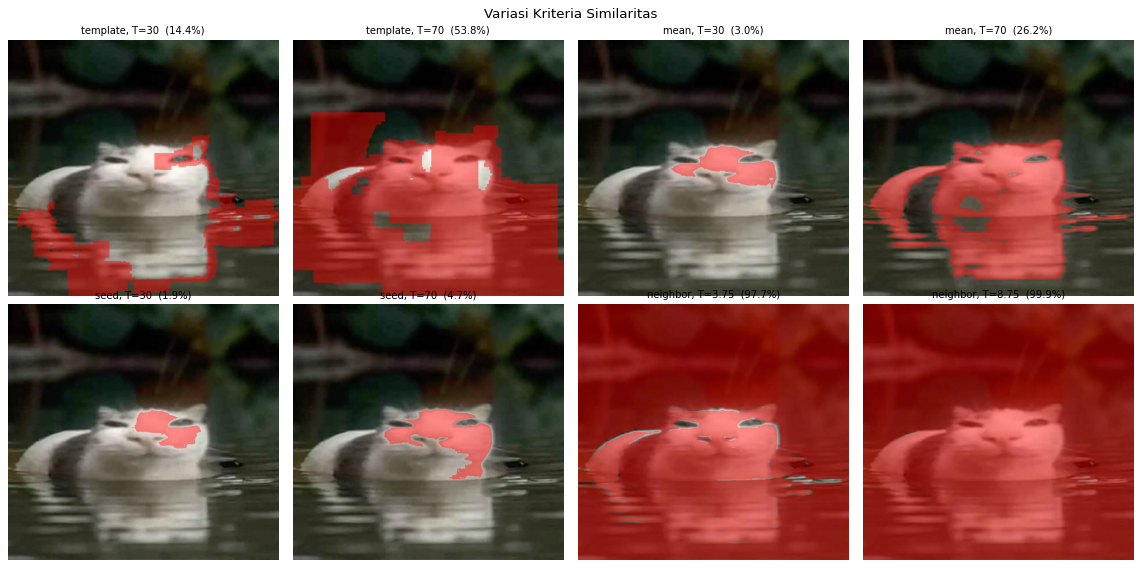

In [6]:
# B.2 Variasi kriteria similaritas
ims, tts = [], []
for crit in ['template', 'mean', 'seed', 'neighbor']:
    for t in [30, 70]:
        thr = t if crit != 'neighbor' else t / 8
        seg = region_growing_ex(img, seed_point, thr, criterion=crit)
        ims.append(overlay(img_rgb, seg))
        tts.append(f'{crit}, T={thr:g}  ({area_pct(seg):.1f}%)')
show_grid(ims, tts, cols=4, size=3.6, suptitle='Variasi Kriteria Similaritas')

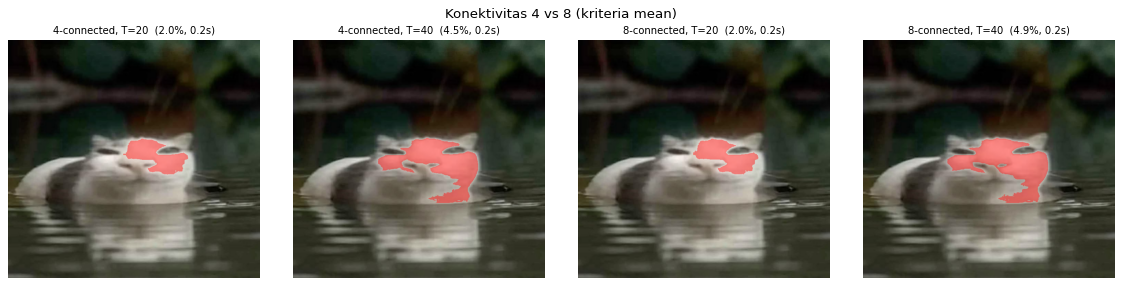

In [7]:
# B.3 Variasi konektivitas (4 vs 8 tetangga)
ims, tts = [], []
for conn in [4, 8]:
    for t in [20, 40]:
        t0 = time.time()
        seg = region_growing_ex(img, seed_point, t, criterion='mean', connectivity=conn)
        ims.append(overlay(img_rgb, seg))
        tts.append(f'{conn}-connected, T={t}  ({area_pct(seg):.1f}%, {time.time()-t0:.1f}s)')
show_grid(ims, tts, cols=4, size=3.6, suptitle='Konektivitas 4 vs 8 (kriteria mean)')

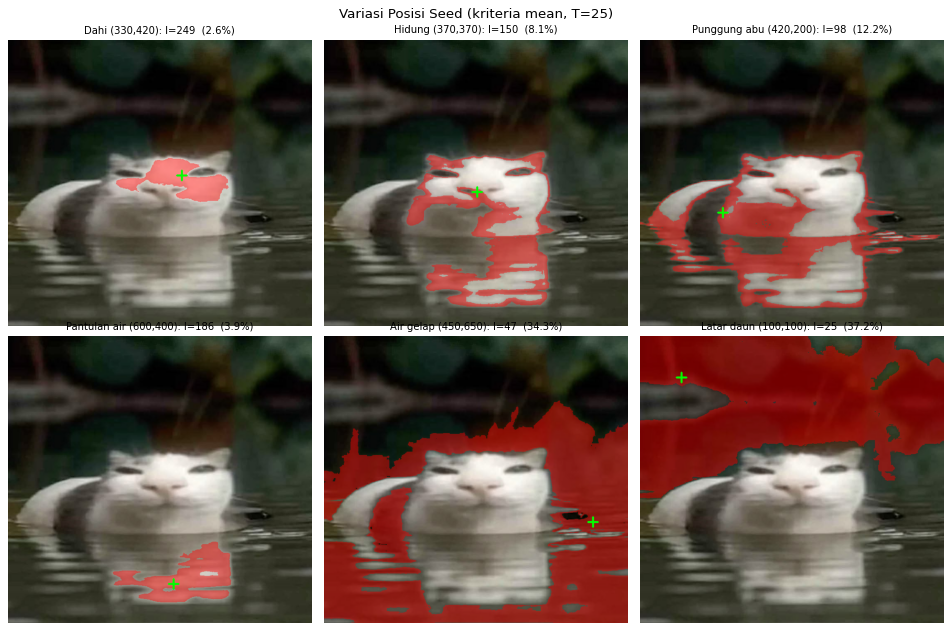

In [8]:
# B.4 Variasi posisi seed point
seeds = {
    'Dahi (330,420)': (330, 420),
    'Hidung (370,370)': (370, 370),
    'Punggung abu (420,200)': (420, 200),
    'Pantulan air (600,400)': (600, 400),
    'Air gelap (450,650)': (450, 650),
    'Latar daun (100,100)': (100, 100),
}
ims, tts = [], []
for name, sp in seeds.items():
    seg = region_growing_ex(img, sp, 25, criterion='mean')
    vis = overlay(img_rgb, seg)
    cv2.drawMarker(vis, (sp[1], sp[0]), (0, 255, 0), cv2.MARKER_CROSS, 25, 3)
    ims.append(vis)
    tts.append(f'{name}: I={img[sp]}  ({area_pct(seg):.1f}%)')
show_grid(ims, tts, cols=3, size=4, suptitle='Variasi Posisi Seed (kriteria mean, T=25)')

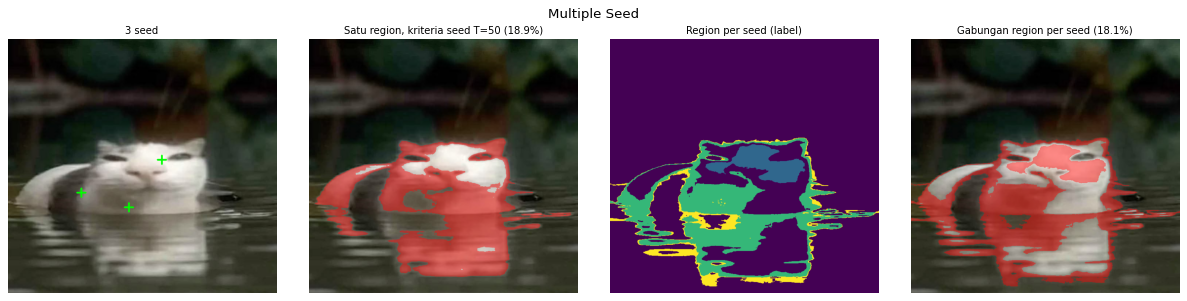

In [9]:
# B.5 Multiple seed
multi = [(330, 420), (420, 200), (460, 330)]
seg_joint = region_growing_ex(img, multi, 50, criterion='seed')

label_map = np.zeros(img.shape, np.uint8)
for i, sp in enumerate(multi, start=1):
    r = region_growing_ex(img, sp, 25, criterion='mean')
    label_map[(r > 0) & (label_map == 0)] = i
seg_union = (label_map > 0).astype(np.uint8) * 255

vis = img_rgb.copy()
for sp in multi:
    cv2.drawMarker(vis, (sp[1], sp[0]), (0, 255, 0), cv2.MARKER_CROSS, 25, 3)
show_grid([vis, overlay(img_rgb, seg_joint), label_map, overlay(img_rgb, seg_union)],
          ['3 seed', f'Satu region, kriteria seed T=50 ({area_pct(seg_joint):.1f}%)',
           'Region per seed (label)', f'Gabungan region per seed ({area_pct(seg_union):.1f}%)'],
          cols=4, size=3.8, cmap='viridis', suptitle='Multiple Seed')

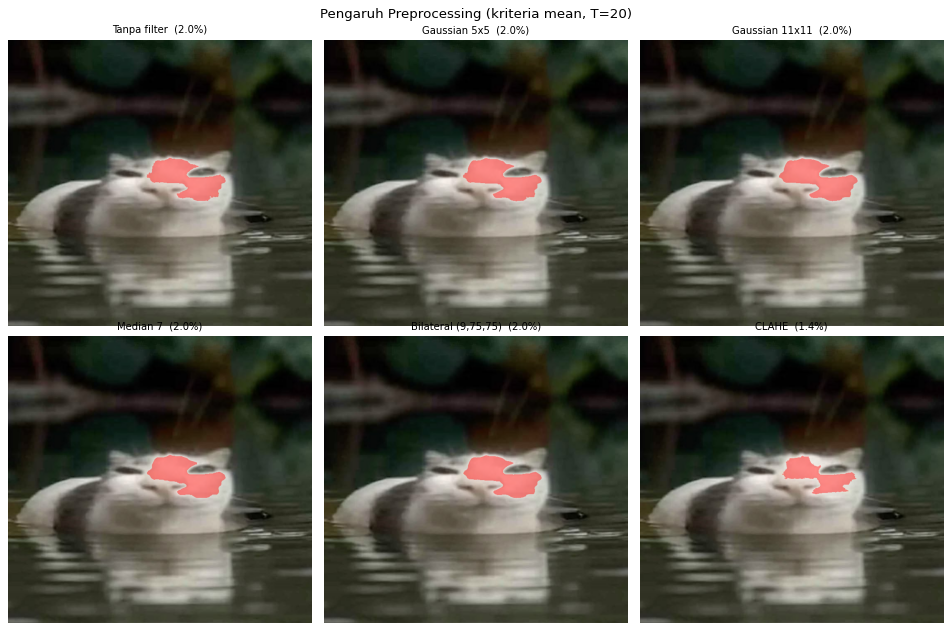

In [10]:
# B.6 Preprocessing sebelum region growing
pre = {
    'Tanpa filter': img,
    'Gaussian 5x5': cv2.GaussianBlur(img, (5, 5), 0),
    'Gaussian 11x11': cv2.GaussianBlur(img, (11, 11), 0),
    'Median 7': cv2.medianBlur(img, 7),
    'Bilateral (9,75,75)': cv2.bilateralFilter(img, 9, 75, 75),
    'CLAHE': cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img),
}
ims, tts = [], []
for name, im in pre.items():
    seg = region_growing_ex(im, seed_point, 20, criterion='mean')
    ims.append(overlay(img_rgb, seg))
    tts.append(f'{name}  ({area_pct(seg):.1f}%)')
show_grid(ims, tts, cols=3, size=4, suptitle='Pengaruh Preprocessing (kriteria mean, T=20)')

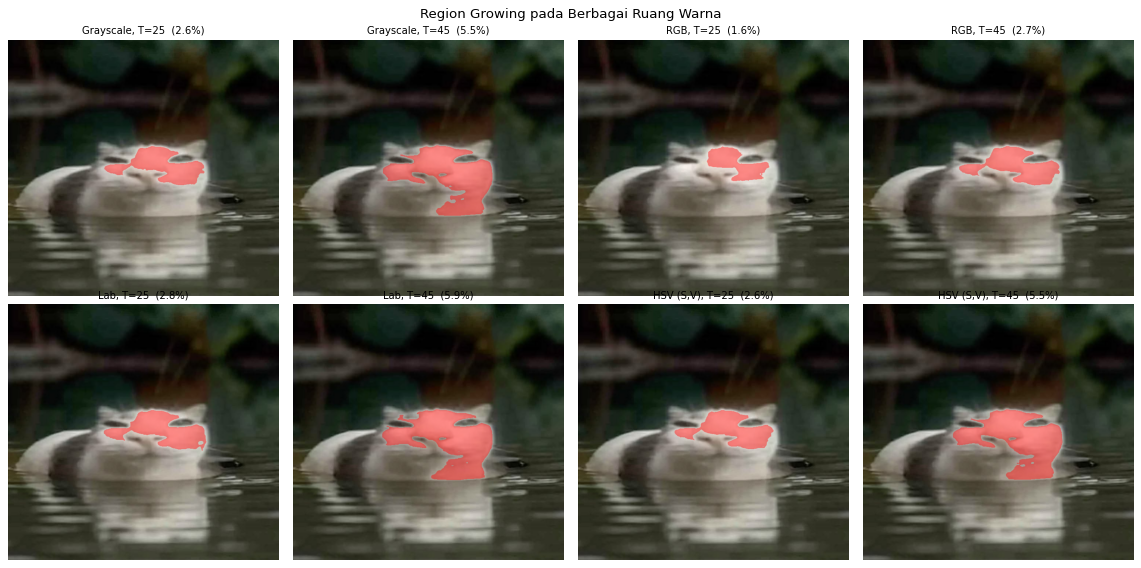

In [11]:
# B.7 Region growing berbasis warna
blur_c = cv2.GaussianBlur(img_color, (5, 5), 0)
spaces = {
    'Grayscale': cv2.cvtColor(blur_c, cv2.COLOR_BGR2GRAY),
    'RGB': cv2.cvtColor(blur_c, cv2.COLOR_BGR2RGB),
    'Lab': cv2.cvtColor(blur_c, cv2.COLOR_BGR2LAB),
    'HSV (S,V)': cv2.cvtColor(blur_c, cv2.COLOR_BGR2HSV)[:, :, 1:],
}
ims, tts = [], []
for name, im in spaces.items():
    for t in [25, 45]:
        seg = region_growing_ex(im, seed_point, t, criterion='mean')
        ims.append(overlay(img_rgb, seg))
        tts.append(f'{name}, T={t}  ({area_pct(seg):.1f}%)')
show_grid(ims, tts, cols=4, size=3.6, suptitle='Region Growing pada Berbagai Ruang Warna')

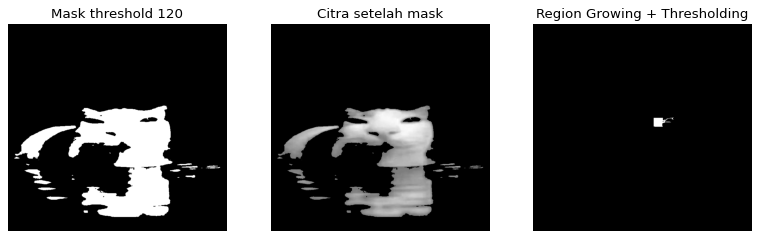

In [12]:
# C. Integrasi dengan Thresholding dan Deteksi Tepi
# C.1 Region Growing + Thresholding (template, T=120) dan variasi threshold pre-mask
_, binary_mask = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY)
pre_masked = cv2.bitwise_and(img, img, mask=binary_mask)
region = region_growing(pre_masked, seed_point, 10)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(binary_mask, cmap='gray'), plt.title('Mask threshold 120'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(pre_masked, cmap='gray'), plt.title('Citra setelah mask'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(region, cmap='gray'), plt.title('Region Growing + Thresholding'), plt.axis('off')
plt.show()

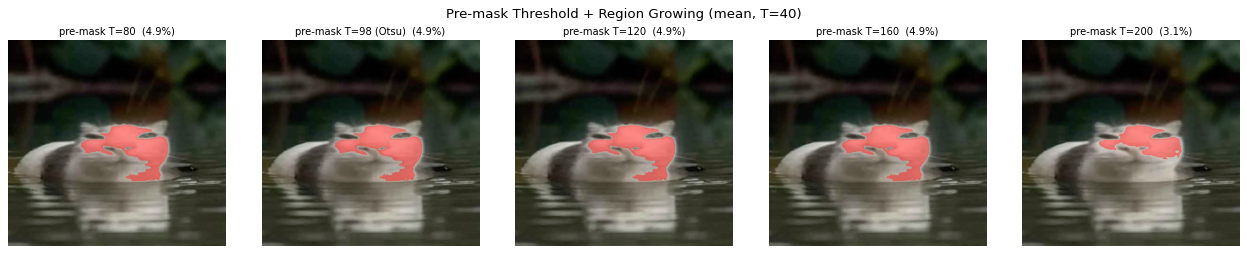

In [13]:
T_otsu, _ = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
ims, tts = [], []
for tm in [80, int(T_otsu), 120, 160, 200]:
    _, bm = cv2.threshold(img, tm, 255, cv2.THRESH_BINARY)
    pm = cv2.bitwise_and(img, img, mask=bm)
    r = region_growing_ex(pm, seed_point, 40, criterion='mean')
    ims.append(overlay(img_rgb, r))
    tts.append(f'pre-mask T={tm}{" (Otsu)" if tm == int(T_otsu) else ""}  ({area_pct(r):.1f}%)')
show_grid(ims, tts, cols=5, size=3.2, suptitle='Pre-mask Threshold + Region Growing (mean, T=40)')

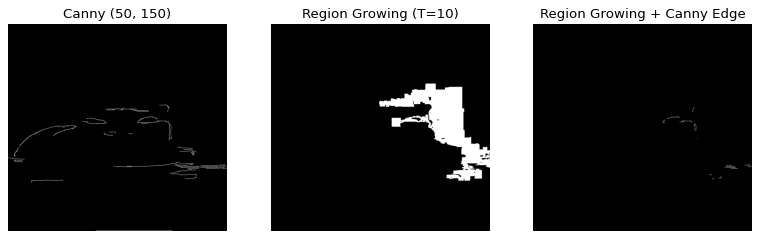

In [14]:
# C.2 Region Growing + Deteksi Tepi (template: AND dengan Canny)
edges = cv2.Canny(img, 50, 150)
region = region_growing(img, seed_point, 10)
combined = cv2.bitwise_and(region, edges)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(edges, cmap='gray'), plt.title('Canny (50, 150)'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(region, cmap='gray'), plt.title('Region Growing (T=10)'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(combined, cmap='gray'), plt.title('Region Growing + Canny Edge'), plt.axis('off')
plt.show()

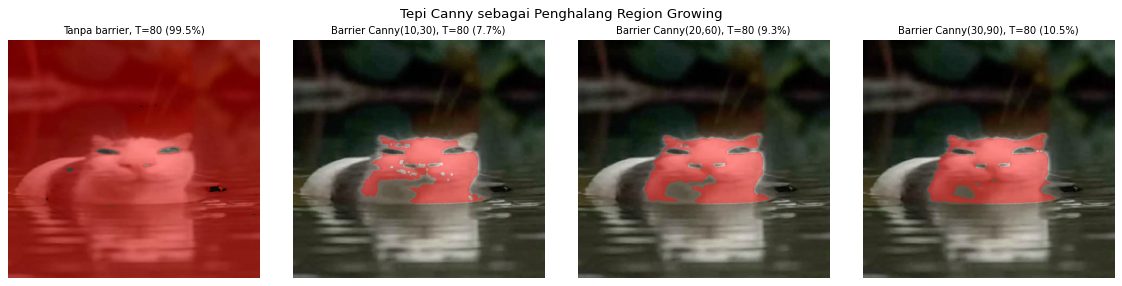

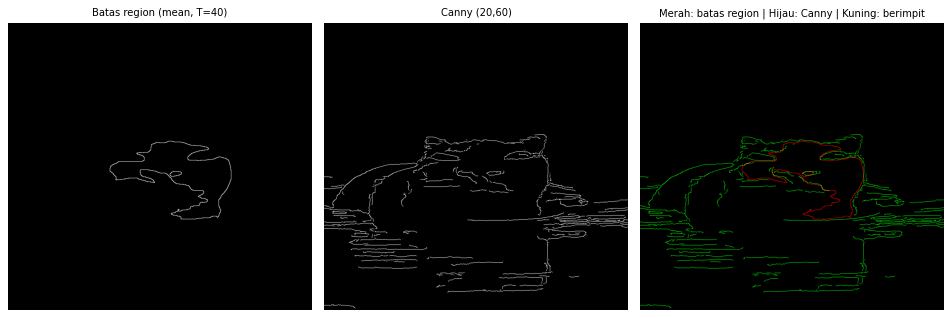

In [15]:
blur = cv2.GaussianBlur(img, (5, 5), 0)
seg_big = region_growing_ex(blur, seed_point, 80, criterion='mean')

ims = [overlay(img_rgb, seg_big)]
tts = [f'Tanpa barrier, T=80 ({area_pct(seg_big):.1f}%)']
for lo, hi in [(10, 30), (20, 60), (30, 90)]:
    e = cv2.Canny(blur, lo, hi)
    bar = cv2.dilate(e, np.ones((3, 3), np.uint8)) > 0
    seg_b = region_growing_ex(blur, seed_point, 80, criterion='mean', barrier=bar)
    seg_b = cv2.morphologyEx(seg_b, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    ims.append(overlay(img_rgb, seg_b))
    tts.append(f'Barrier Canny({lo},{hi}), T=80 ({area_pct(seg_b):.1f}%)')
    if (lo, hi) == (20, 60):
        seg_barrier = seg_b
show_grid(ims, tts, cols=4, size=3.6, suptitle='Tepi Canny sebagai Penghalang Region Growing')

seg_40 = region_growing_ex(blur, seed_point, 40, criterion='mean')
boundary = cv2.subtract(seg_40, cv2.erode(seg_40, np.ones((3, 3), np.uint8)))
e = cv2.Canny(blur, 20, 60)
vis = np.dstack([boundary, e, np.zeros_like(e)])
show_grid([boundary, e, vis], ['Batas region (mean, T=40)', 'Canny (20,60)', 'Merah: batas region | Hijau: Canny | Kuning: berimpit'],
          cols=3, size=4)

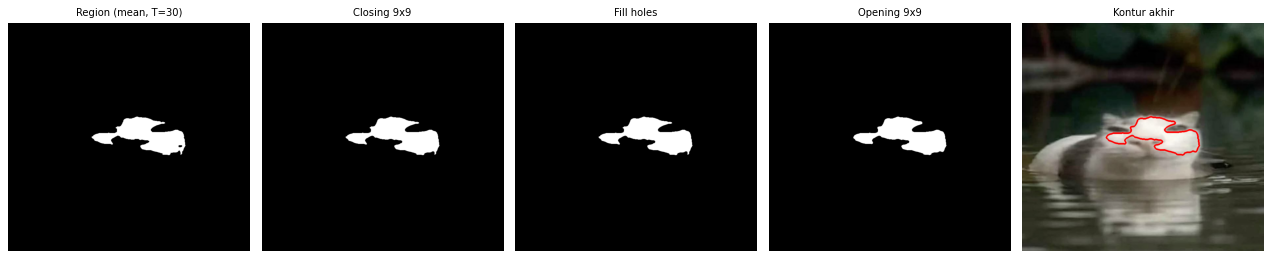

In [16]:
# C.3 Post-processing morfologi
from scipy.ndimage import binary_fill_holes

base = region_growing_ex(blur, seed_point, 30, criterion='mean')
ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
closed = cv2.morphologyEx(base, cv2.MORPH_CLOSE, ker)
filled = binary_fill_holes(closed > 0).astype(np.uint8) * 255
opened = cv2.morphologyEx(filled, cv2.MORPH_OPEN, ker)

contours, _ = cv2.findContours(opened, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
vis = img_rgb.copy()
cv2.drawContours(vis, contours, -1, (255, 0, 0), 3)
show_grid([base, closed, filled, opened, vis],
          [f'Region (mean, T=30)', 'Closing 9x9', 'Fill holes', 'Opening 9x9', 'Kontur akhir'], cols=5, size=3.2)

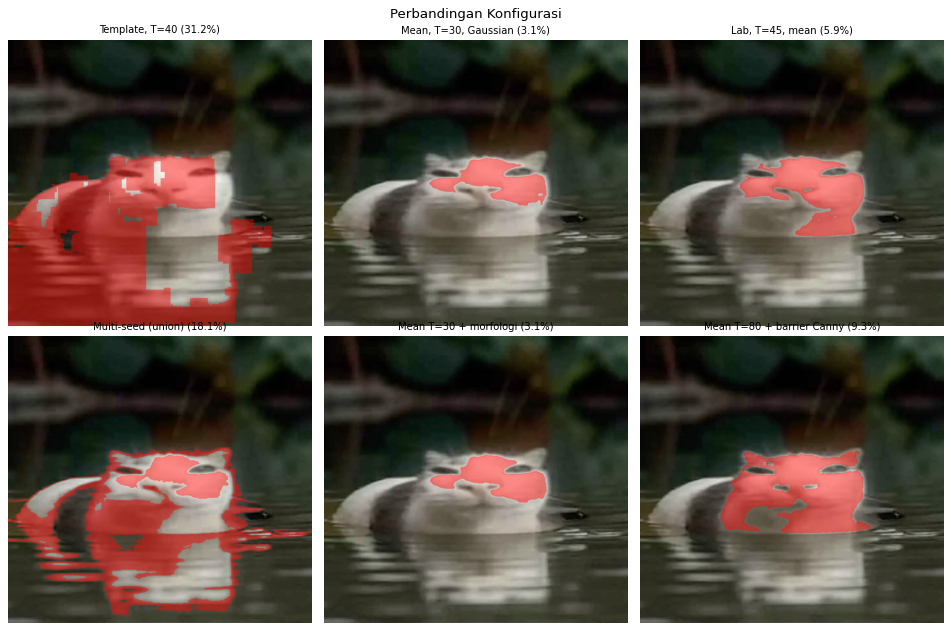

In [17]:
# D. Ringkasan: perbandingan konfigurasi terbaik
configs = {
    'Template, T=40': region_growing_ex(img, seed_point, 40, 'template'),
    'Mean, T=30, Gaussian': region_growing_ex(blur, seed_point, 30, 'mean'),
    'Lab, T=45, mean': region_growing_ex(spaces['Lab'], seed_point, 45, 'mean'),
    'Multi-seed (union)': seg_union,
    'Mean T=30 + morfologi': opened,
    'Mean T=80 + barrier Canny': seg_barrier,
}
ims = [overlay(img_rgb, m) for m in configs.values()]
show_grid(ims, [f'{k} ({area_pct(v):.1f}%)' for k, v in configs.items()], cols=3, size=4, suptitle='Perbandingan Konfigurasi')